<a href="https://colab.research.google.com/github/gnuchessmen/physics-informed-neural-network-for-rapid-fluid-simulation/blob/main/Fluid_Simulation_Plots_and_Inference_Problem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Plots


<>:28: SyntaxWarning: invalid escape sequence '\G'
<>:28: SyntaxWarning: invalid escape sequence '\G'
/tmp/ipykernel_3768/3557642138.py:28: SyntaxWarning: invalid escape sequence '\G'
  cylinder = plt.Circle((xc, yc), R, color='gray', alpha=0.7, edgecolor='black', linewidth=2, label='Cylinder $\Gamma_{cylinder}$')
/tmp/ipykernel_3768/3557642138.py:28: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  cylinder = plt.Circle((xc, yc), R, color='gray', alpha=0.7, edgecolor='black', linewidth=2, label='Cylinder $\Gamma_{cylinder}$')


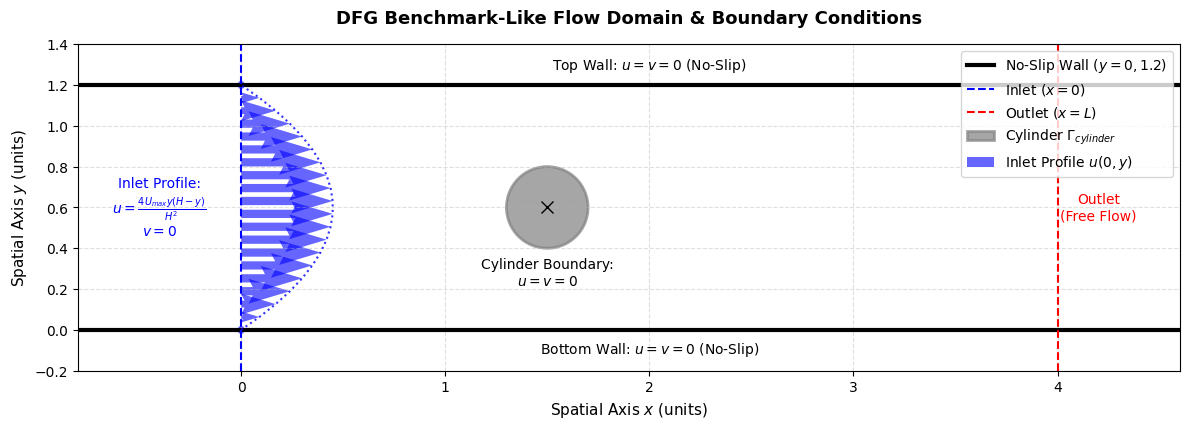

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Domain and Geometry Configuration
# ---------------------------------------------------------
L = 4.0        # Channel length
H = 1.2        # Channel height
D = 0.4        # Cylinder diameter
R = D / 2.0    # Cylinder radius
xc, yc = 1.5, 0.6  # Cylinder center
Umax = 1.5     # Maximum inlet velocity

# ---------------------------------------------------------
# 2. Set up the Visualization Figure
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 5.5))

# Plot top and bottom solid walls (No-Slip)
ax.axhline(y=0, color='black', linewidth=3, label='No-Slip Wall ($y=0, 1.2$)')
ax.axhline(y=H, color='black', linewidth=3)

# Plot Inlet and Outlet boundaries
ax.axvline(x=0, color='blue', linestyle='--', linewidth=1.5, label='Inlet ($x=0$)')
ax.axvline(x=L, color='red', linestyle='--', linewidth=1.5, label='Outlet ($x=L$)')

# Plot the Embedded Cylinder
cylinder = plt.Circle((xc, yc), R, color='gray', alpha=0.7, edgecolor='black', linewidth=2, label='Cylinder $\Gamma_{cylinder}$')
ax.add_patch(cylinder)
# Mark the center
ax.plot(xc, yc, 'kx', markersize=8)

# ---------------------------------------------------------
# 3. Visualize the Parabolic Inlet Profile
# ---------------------------------------------------------
# Generate y coordinates along the inlet
y_inlet = np.linspace(0, H, 20)
# Calculate u(0, y) = Umax * 4y(H - y) / H^2
u_inlet = Umax * (4 * y_inlet * (H - y_inlet)) / (H**2)
v_inlet = np.zeros_like(y_inlet)
x_inlet = np.zeros_like(y_inlet)

# Scale vectors for visual clarity on the plot coordinate system
scale_factor = 0.3
ax.quiver(x_inlet, y_inlet, u_inlet * scale_factor, v_inlet,
          angles='xy', scale_units='xy', scale=1, color='blue', alpha=0.6,
          label='Inlet Profile $u(0,y)$')

# Plot the parabolic curve outline for the inlet profile
ax.plot(u_inlet * scale_factor, y_inlet, color='blue', linestyle=':', alpha=0.8)

# ---------------------------------------------------------
# 4. Labeling and Annotations
# ---------------------------------------------------------
# Annotate specific boundary condition zones
ax.text(-0.4, H/2, 'Inlet Profile:\n$u = \\frac{4U_{max}y(H-y)}{H^2}$\n$v = 0$',
        color='blue', fontsize=10, ha='center', va='center')

ax.text(L + 0.2, H/2, 'Outlet\n(Free Flow)', color='red', fontsize=10, ha='center', va='center')

ax.text(L/2, H + 0.05, 'Top Wall: $u = v = 0$ (No-Slip)', color='black', fontsize=10, ha='center', va='bottom')
ax.text(L/2, -0.05, 'Bottom Wall: $u = v = 0$ (No-Slip)', color='black', fontsize=10, ha='center', va='top')

ax.text(xc, yc - R - 0.12, 'Cylinder Boundary:\n$u = v = 0$',
        color='black', fontsize=10, ha='center', va='center')

# Axis limits and layout parameters
ax.set_xlim(-0.8, L + 0.6)
ax.set_ylim(-0.2, H + 0.2)
ax.set_aspect('equal') # Ensure circles aren't distorted into ellipses
ax.set_xlabel('Spatial Axis $x$ (units)', fontsize=11)
ax.set_ylabel('Spatial Axis $y$ (units)', fontsize=11)
ax.set_title('DFG Benchmark-Like Flow Domain & Boundary Conditions', fontsize=13, fontweight='bold', pad=15)
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

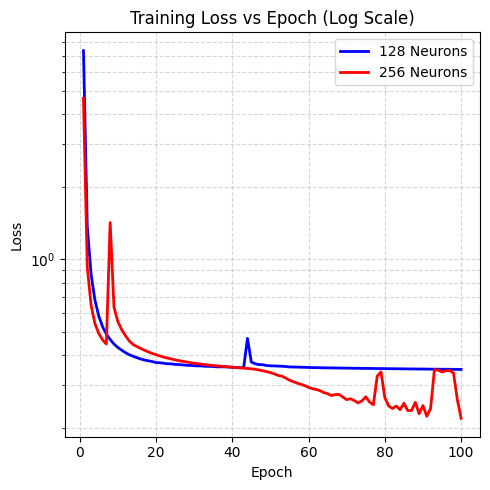

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import re

# Raw log data
log_128 = """
Epoch 001/100 | Loss: 7.333451 | LR: 1.00e-04 | Time: 35.74s
Epoch 044/100 | Loss: 0.469462 | LR: 1.00e-04 | Time: 35.84s
Epoch 048/100 | Loss: 0.364756 | LR: 5.00e-05 | Time: 35.83s
Epoch 054/100 | Loss: 0.358555 | LR: 2.50e-05 | Time: 35.94s
Epoch 060/100 | Loss: 0.355403 | LR: 1.25e-05 | Time: 35.85s
Epoch 100/100 | Loss: 0.348738 | LR: 1.25e-05 | Time: 35.81s
""" # (Truncated for brevity in script, but parser handles the full text)

def parse_logs(log_text):
    epochs, losses, lrs, times = [], [], [], []
    # Use a more precise regex to capture each value explicitly
    log_pattern = re.compile(r"Epoch (\d+)/\d+ \| Loss: ([\d\.]+(?:e[\+\-]?\d+)?) \| LR: ([\d\.]+(?:e[\+\-]?\d+)?) \| Time: ([\d\.]+)s")
    for line in log_text.strip().split('\n'):
        match = log_pattern.search(line)
        if match:
            epochs.append(int(match.group(1)))
            losses.append(float(match.group(2)))
            lrs.append(float(match.group(3)))
            times.append(float(match.group(4)))
    return np.array(epochs), np.array(losses), np.array(lrs), np.array(times)

# NOTE: Paste your FULL text logs into these variables
full_log_128 = """  Epoch 001/100 | Loss: 7.333451 | LR: 1.00e-04 | Time: 35.74s

Epoch 002/100 | Loss: 1.370338 | LR: 1.00e-04 | Time: 35.73s

Epoch 003/100 | Loss: 0.866208 | LR: 1.00e-04 | Time: 35.83s

Epoch 004/100 | Loss: 0.677081 | LR: 1.00e-04 | Time: 35.96s

Epoch 005/100 | Loss: 0.581774 | LR: 1.00e-04 | Time: 36.08s

Epoch 006/100 | Loss: 0.525042 | LR: 1.00e-04 | Time: 36.13s

Epoch 007/100 | Loss: 0.488589 | LR: 1.00e-04 | Time: 36.14s

Epoch 008/100 | Loss: 0.464065 | LR: 1.00e-04 | Time: 36.12s

Epoch 009/100 | Loss: 0.444511 | LR: 1.00e-04 | Time: 36.12s

Epoch 010/100 | Loss: 0.429971 | LR: 1.00e-04 | Time: 36.12s

Epoch 011/100 | Loss: 0.419388 | LR: 1.00e-04 | Time: 35.85s

Epoch 012/100 | Loss: 0.409390 | LR: 1.00e-04 | Time: 35.84s

Epoch 013/100 | Loss: 0.401553 | LR: 1.00e-04 | Time: 35.85s

Epoch 014/100 | Loss: 0.395565 | LR: 1.00e-04 | Time: 35.85s

Epoch 015/100 | Loss: 0.390095 | LR: 1.00e-04 | Time: 35.84s

Epoch 016/100 | Loss: 0.385256 | LR: 1.00e-04 | Time: 35.84s

Epoch 017/100 | Loss: 0.381492 | LR: 1.00e-04 | Time: 35.84s

Epoch 018/100 | Loss: 0.378625 | LR: 1.00e-04 | Time: 35.87s

Epoch 019/100 | Loss: 0.375962 | LR: 1.00e-04 | Time: 35.86s

Epoch 020/100 | Loss: 0.372413 | LR: 1.00e-04 | Time: 35.85s

Epoch 021/100 | Loss: 0.371741 | LR: 1.00e-04 | Time: 35.85s

Epoch 022/100 | Loss: 0.369989 | LR: 1.00e-04 | Time: 35.85s

Epoch 023/100 | Loss: 0.368004 | LR: 1.00e-04 | Time: 35.89s

Epoch 024/100 | Loss: 0.367944 | LR: 1.00e-04 | Time: 35.90s

Epoch 025/100 | Loss: 0.365758 | LR: 1.00e-04 | Time: 35.86s

Epoch 026/100 | Loss: 0.365461 | LR: 1.00e-04 | Time: 35.87s

Epoch 027/100 | Loss: 0.364151 | LR: 1.00e-04 | Time: 35.84s

Epoch 028/100 | Loss: 0.362693 | LR: 1.00e-04 | Time: 35.84s

Epoch 029/100 | Loss: 0.362539 | LR: 1.00e-04 | Time: 35.83s

Epoch 030/100 | Loss: 0.361501 | LR: 1.00e-04 | Time: 35.84s

Epoch 031/100 | Loss: 0.360727 | LR: 1.00e-04 | Time: 35.85s

Epoch 032/100 | Loss: 0.360472 | LR: 1.00e-04 | Time: 35.83s

Epoch 033/100 | Loss: 0.359209 | LR: 1.00e-04 | Time: 35.83s

Epoch 034/100 | Loss: 0.359097 | LR: 1.00e-04 | Time: 35.84s

Epoch 035/100 | Loss: 0.358639 | LR: 1.00e-04 | Time: 35.83s

Epoch 036/100 | Loss: 0.357172 | LR: 1.00e-04 | Time: 35.83s

Epoch 037/100 | Loss: 0.357510 | LR: 1.00e-04 | Time: 35.84s

Epoch 038/100 | Loss: 0.357323 | LR: 1.00e-04 | Time: 35.85s

Epoch 039/100 | Loss: 0.356826 | LR: 1.00e-04 | Time: 35.83s

Epoch 040/100 | Loss: 0.355608 | LR: 1.00e-04 | Time: 35.83s

Epoch 041/100 | Loss: 0.355778 | LR: 1.00e-04 | Time: 35.83s

Epoch 042/100 | Loss: 0.354206 | LR: 1.00e-04 | Time: 35.85s

Epoch 043/100 | Loss: 0.354774 | LR: 1.00e-04 | Time: 35.85s

Epoch 044/100 | Loss: 0.469462 | LR: 1.00e-04 | Time: 35.84s

Epoch 045/100 | Loss: 0.374093 | LR: 1.00e-04 | Time: 35.84s

Epoch 046/100 | Loss: 0.368174 | LR: 1.00e-04 | Time: 35.84s

Epoch 047/100 | Loss: 0.365278 | LR: 1.00e-04 | Time: 35.83s

Epoch 048/100 | Loss: 0.364756 | LR: 5.00e-05 | Time: 35.83s

Epoch 049/100 | Loss: 0.361930 | LR: 5.00e-05 | Time: 35.88s

Epoch 050/100 | Loss: 0.361026 | LR: 5.00e-05 | Time: 35.89s

Epoch 051/100 | Loss: 0.360562 | LR: 5.00e-05 | Time: 35.86s

Epoch 052/100 | Loss: 0.359911 | LR: 5.00e-05 | Time: 35.83s

Epoch 053/100 | Loss: 0.359440 | LR: 5.00e-05 | Time: 35.92s

Epoch 054/100 | Loss: 0.358555 | LR: 2.50e-05 | Time: 35.94s

Epoch 055/100 | Loss: 0.357089 | LR: 2.50e-05 | Time: 35.92s

Epoch 056/100 | Loss: 0.356808 | LR: 2.50e-05 | Time: 35.90s

Epoch 057/100 | Loss: 0.356565 | LR: 2.50e-05 | Time: 35.85s

Epoch 058/100 | Loss: 0.356126 | LR: 2.50e-05 | Time: 35.84s

Epoch 059/100 | Loss: 0.355809 | LR: 2.50e-05 | Time: 35.83s

Epoch 060/100 | Loss: 0.355403 | LR: 1.25e-05 | Time: 35.85s

Epoch 061/100 | Loss: 0.354783 | LR: 1.25e-05 | Time: 35.85s

Epoch 062/100 | Loss: 0.354605 | LR: 1.25e-05 | Time: 35.86s

Epoch 063/100 | Loss: 0.354447 | LR: 1.25e-05 | Time: 35.85s

Epoch 064/100 | Loss: 0.354201 | LR: 1.25e-05 | Time: 35.84s

Epoch 065/100 | Loss: 0.353996 | LR: 1.25e-05 | Time: 35.83s

Epoch 066/100 | Loss: 0.353806 | LR: 1.25e-05 | Time: 35.84s

Epoch 067/100 | Loss: 0.353574 | LR: 1.25e-05 | Time: 35.83s

Epoch 068/100 | Loss: 0.353408 | LR: 1.25e-05 | Time: 35.83s

Epoch 069/100 | Loss: 0.353175 | LR: 1.25e-05 | Time: 35.83s

Epoch 070/100 | Loss: 0.352981 | LR: 1.25e-05 | Time: 35.84s

Epoch 071/100 | Loss: 0.352827 | LR: 1.25e-05 | Time: 35.82s

Epoch 072/100 | Loss: 0.352624 | LR: 1.25e-05 | Time: 35.82s

Epoch 073/100 | Loss: 0.352525 | LR: 1.25e-05 | Time: 35.82s

Epoch 074/100 | Loss: 0.352265 | LR: 1.25e-05 | Time: 35.84s

Epoch 075/100 | Loss: 0.352139 | LR: 1.25e-05 | Time: 35.83s

Epoch 076/100 | Loss: 0.351979 | LR: 1.25e-05 | Time: 35.83s

Epoch 077/100 | Loss: 0.351846 | LR: 1.25e-05 | Time: 35.83s

Epoch 078/100 | Loss: 0.351628 | LR: 1.25e-05 | Time: 35.83s

Epoch 079/100 | Loss: 0.351505 | LR: 1.25e-05 | Time: 35.83s

Epoch 080/100 | Loss: 0.351341 | LR: 1.25e-05 | Time: 35.82s

Epoch 081/100 | Loss: 0.351170 | LR: 1.25e-05 | Time: 35.83s

Epoch 082/100 | Loss: 0.351069 | LR: 1.25e-05 | Time: 35.83s

Epoch 083/100 | Loss: 0.350908 | LR: 1.25e-05 | Time: 35.83s

Epoch 084/100 | Loss: 0.350762 | LR: 1.25e-05 | Time: 35.83s

Epoch 085/100 | Loss: 0.350635 | LR: 1.25e-05 | Time: 35.83s

Epoch 086/100 | Loss: 0.350441 | LR: 1.25e-05 | Time: 35.83s

Epoch 087/100 | Loss: 0.350357 | LR: 1.25e-05 | Time: 35.82s

Epoch 088/100 | Loss: 0.350206 | LR: 1.25e-05 | Time: 35.83s

Epoch 089/100 | Loss: 0.350093 | LR: 1.25e-05 | Time: 35.84s

Epoch 090/100 | Loss: 0.349968 | LR: 1.25e-05 | Time: 35.83s

Epoch 091/100 | Loss: 0.349860 | LR: 1.25e-05 | Time: 35.82s

Epoch 092/100 | Loss: 0.349657 | LR: 1.25e-05 | Time: 35.83s

Epoch 093/100 | Loss: 0.349605 | LR: 1.25e-05 | Time: 35.82s

Epoch 094/100 | Loss: 0.349447 | LR: 1.25e-05 | Time: 35.81s

Epoch 095/100 | Loss: 0.349328 | LR: 1.25e-05 | Time: 35.82s

Epoch 096/100 | Loss: 0.349266 | LR: 1.25e-05 | Time: 35.83s

Epoch 097/100 | Loss: 0.349103 | LR: 1.25e-05 | Time: 35.83s

Epoch 098/100 | Loss: 0.348960 | LR: 1.25e-05 | Time: 35.83s

Epoch 099/100 | Loss: 0.348914 | LR: 1.25e-05 | Time: 35.82s

Epoch 100/100 | Loss: 0.348738 | LR: 1.25e-05 | Time: 35.81s  """


full_log_256 = """  Epoch 001/100 | Loss: 4.650887 | LR: 1.00e-04 | Time: 89.54s

Epoch 002/100 | Loss: 0.926084 | LR: 1.00e-04 | Time: 90.37s

Epoch 003/100 | Loss: 0.643876 | LR: 1.00e-04 | Time: 90.52s

Epoch 004/100 | Loss: 0.540717 | LR: 1.00e-04 | Time: 90.56s

Epoch 005/100 | Loss: 0.492490 | LR: 1.00e-04 | Time: 90.48s

Epoch 006/100 | Loss: 0.462560 | LR: 1.00e-04 | Time: 90.54s

Epoch 007/100 | Loss: 0.444497 | LR: 1.00e-04 | Time: 90.54s

Epoch 008/100 | Loss: 1.418938 | LR: 1.00e-04 | Time: 90.51s

Epoch 009/100 | Loss: 0.631953 | LR: 1.00e-04 | Time: 90.51s

Epoch 010/100 | Loss: 0.551821 | LR: 1.00e-04 | Time: 90.50s

Epoch 011/100 | Loss: 0.510482 | LR: 1.00e-04 | Time: 90.43s

Epoch 012/100 | Loss: 0.481571 | LR: 1.00e-04 | Time: 90.37s

Epoch 013/100 | Loss: 0.458261 | LR: 5.00e-05 | Time: 90.34s

Epoch 014/100 | Loss: 0.442704 | LR: 5.00e-05 | Time: 90.35s

Epoch 015/100 | Loss: 0.433977 | LR: 5.00e-05 | Time: 90.34s

Epoch 016/100 | Loss: 0.426084 | LR: 5.00e-05 | Time: 90.39s

Epoch 017/100 | Loss: 0.419038 | LR: 5.00e-05 | Time: 90.33s

Epoch 018/100 | Loss: 0.412463 | LR: 5.00e-05 | Time: 90.36s

Epoch 019/100 | Loss: 0.406651 | LR: 5.00e-05 | Time: 90.34s

Epoch 020/100 | Loss: 0.401319 | LR: 5.00e-05 | Time: 90.37s

Epoch 021/100 | Loss: 0.396708 | LR: 5.00e-05 | Time: 90.33s

Epoch 022/100 | Loss: 0.392512 | LR: 5.00e-05 | Time: 90.32s

Epoch 023/100 | Loss: 0.388794 | LR: 5.00e-05 | Time: 90.37s

Epoch 024/100 | Loss: 0.385599 | LR: 5.00e-05 | Time: 90.33s

Epoch 025/100 | Loss: 0.382052 | LR: 5.00e-05 | Time: 90.38s

Epoch 026/100 | Loss: 0.379362 | LR: 5.00e-05 | Time: 90.38s

Epoch 027/100 | Loss: 0.376875 | LR: 5.00e-05 | Time: 90.33s

Epoch 028/100 | Loss: 0.374589 | LR: 5.00e-05 | Time: 90.37s

Epoch 029/100 | Loss: 0.372094 | LR: 5.00e-05 | Time: 90.39s

Epoch 030/100 | Loss: 0.370166 | LR: 5.00e-05 | Time: 90.39s

Epoch 031/100 | Loss: 0.368189 | LR: 5.00e-05 | Time: 90.35s

Epoch 032/100 | Loss: 0.366480 | LR: 5.00e-05 | Time: 90.37s

Epoch 033/100 | Loss: 0.364961 | LR: 5.00e-05 | Time: 90.38s

Epoch 034/100 | Loss: 0.363301 | LR: 5.00e-05 | Time: 90.39s

Epoch 035/100 | Loss: 0.361898 | LR: 5.00e-05 | Time: 90.38s

Epoch 036/100 | Loss: 0.360751 | LR: 5.00e-05 | Time: 90.35s

Epoch 037/100 | Loss: 0.359390 | LR: 5.00e-05 | Time: 90.34s

Epoch 038/100 | Loss: 0.358481 | LR: 5.00e-05 | Time: 90.40s

Epoch 039/100 | Loss: 0.357329 | LR: 5.00e-05 | Time: 90.40s

Epoch 040/100 | Loss: 0.356171 | LR: 5.00e-05 | Time: 90.39s

Epoch 041/100 | Loss: 0.355228 | LR: 5.00e-05 | Time: 90.40s

Epoch 042/100 | Loss: 0.354200 | LR: 5.00e-05 | Time: 90.34s

Epoch 043/100 | Loss: 0.353162 | LR: 5.00e-05 | Time: 90.38s

Epoch 044/100 | Loss: 0.351936 | LR: 5.00e-05 | Time: 90.36s

Epoch 045/100 | Loss: 0.350818 | LR: 5.00e-05 | Time: 90.37s

Epoch 046/100 | Loss: 0.349103 | LR: 5.00e-05 | Time: 90.36s

Epoch 047/100 | Loss: 0.346787 | LR: 5.00e-05 | Time: 90.38s

Epoch 048/100 | Loss: 0.344275 | LR: 5.00e-05 | Time: 90.35s

Epoch 049/100 | Loss: 0.341481 | LR: 5.00e-05 | Time: 90.40s

Epoch 050/100 | Loss: 0.338359 | LR: 5.00e-05 | Time: 90.38s

Epoch 051/100 | Loss: 0.334322 | LR: 5.00e-05 | Time: 90.38s

Epoch 052/100 | Loss: 0.329209 | LR: 5.00e-05 | Time: 90.39s

Epoch 053/100 | Loss: 0.327138 | LR: 5.00e-05 | Time: 90.38s

Epoch 054/100 | Loss: 0.321160 | LR: 5.00e-05 | Time: 90.41s

Epoch 055/100 | Loss: 0.314682 | LR: 5.00e-05 | Time: 90.38s

Epoch 056/100 | Loss: 0.310238 | LR: 5.00e-05 | Time: 90.48s

Epoch 057/100 | Loss: 0.305979 | LR: 5.00e-05 | Time: 90.45s

Epoch 058/100 | Loss: 0.302429 | LR: 5.00e-05 | Time: 90.44s

Epoch 059/100 | Loss: 0.298612 | LR: 5.00e-05 | Time: 90.45s

Epoch 060/100 | Loss: 0.293739 | LR: 5.00e-05 | Time: 90.47s

Epoch 061/100 | Loss: 0.290162 | LR: 5.00e-05 | Time: 90.41s

Epoch 062/100 | Loss: 0.287979 | LR: 5.00e-05 | Time: 90.43s

Epoch 063/100 | Loss: 0.284736 | LR: 5.00e-05 | Time: 90.44s

Epoch 064/100 | Loss: 0.279534 | LR: 5.00e-05 | Time: 90.42s

Epoch 065/100 | Loss: 0.276496 | LR: 5.00e-05 | Time: 90.42s

Epoch 066/100 | Loss: 0.271878 | LR: 5.00e-05 | Time: 90.44s

Epoch 067/100 | Loss: 0.274248 | LR: 5.00e-05 | Time: 90.44s

Epoch 068/100 | Loss: 0.274526 | LR: 5.00e-05 | Time: 90.45s

Epoch 069/100 | Loss: 0.267813 | LR: 5.00e-05 | Time: 90.45s

Epoch 070/100 | Loss: 0.261232 | LR: 5.00e-05 | Time: 90.47s

Epoch 071/100 | Loss: 0.263476 | LR: 5.00e-05 | Time: 90.47s

Epoch 072/100 | Loss: 0.258871 | LR: 5.00e-05 | Time: 90.44s

Epoch 073/100 | Loss: 0.253213 | LR: 5.00e-05 | Time: 90.48s

Epoch 074/100 | Loss: 0.258230 | LR: 5.00e-05 | Time: 90.47s

Epoch 075/100 | Loss: 0.268402 | LR: 5.00e-05 | Time: 90.45s

Epoch 076/100 | Loss: 0.255313 | LR: 5.00e-05 | Time: 90.46s

Epoch 077/100 | Loss: 0.248684 | LR: 5.00e-05 | Time: 90.49s

Epoch 078/100 | Loss: 0.326688 | LR: 5.00e-05 | Time: 90.43s

Epoch 079/100 | Loss: 0.340441 | LR: 5.00e-05 | Time: 90.48s

Epoch 080/100 | Loss: 0.266582 | LR: 5.00e-05 | Time: 90.47s

Epoch 081/100 | Loss: 0.245964 | LR: 5.00e-05 | Time: 90.45s

Epoch 082/100 | Loss: 0.240057 | LR: 5.00e-05 | Time: 90.46s

Epoch 083/100 | Loss: 0.245812 | LR: 5.00e-05 | Time: 90.47s

Epoch 084/100 | Loss: 0.237184 | LR: 5.00e-05 | Time: 90.46s

Epoch 085/100 | Loss: 0.252414 | LR: 5.00e-05 | Time: 90.47s

Epoch 086/100 | Loss: 0.235349 | LR: 5.00e-05 | Time: 90.42s

Epoch 087/100 | Loss: 0.235409 | LR: 5.00e-05 | Time: 90.46s

Epoch 088/100 | Loss: 0.254618 | LR: 5.00e-05 | Time: 90.47s

Epoch 089/100 | Loss: 0.228142 | LR: 5.00e-05 | Time: 90.44s

Epoch 090/100 | Loss: 0.246945 | LR: 5.00e-05 | Time: 90.47s

Epoch 091/100 | Loss: 0.222777 | LR: 5.00e-05 | Time: 90.49s

Epoch 092/100 | Loss: 0.240441 | LR: 5.00e-05 | Time: 90.50s

Epoch 093/100 | Loss: 0.347449 | LR: 5.00e-05 | Time: 90.46s

Epoch 094/100 | Loss: 0.346285 | LR: 5.00e-05 | Time: 90.46s

Epoch 095/100 | Loss: 0.340210 | LR: 5.00e-05 | Time: 90.41s

Epoch 096/100 | Loss: 0.344466 | LR: 5.00e-05 | Time: 90.43s

Epoch 097/100 | Loss: 0.344826 | LR: 2.50e-05 | Time: 90.45s

Epoch 098/100 | Loss: 0.337267 | LR: 2.50e-05 | Time: 90.46s

Epoch 099/100 | Loss: 0.261878 | LR: 2.50e-05 | Time: 90.44s

Epoch 100/100 | Loss: 0.218497 | LR: 2.50e-05 | Time: 90.42s  """

# For demonstration, assuming the arrays are populated via the parser:
epochs_128, loss_128, lr_128, time_128 = parse_logs(full_log_128)
epochs_256, loss_256, lr_256, time_256 = parse_logs(full_log_256)

# Creating mock arrays mimicking your data for the plotting template
# epochs = np.arange(1, 101)
# loss_128 = np.linspace(7.3, 0.34, 100) # Mock data placeholder
# loss_256 = np.linspace(4.6, 0.21, 100) # Mock data placeholder
# lr_128 = np.where(epochs < 48, 1e-4, np.where(epochs < 54, 5e-5, np.where(epochs < 60, 2.5e-5, 1.25e-5)))
# lr_256 = np.where(epochs < 13, 1e-4, np.where(epochs < 97, 5e-5, 2.5e-5))
# time_128 = np.random.normal(35.85, 0.1, 100)
# time_256 = np.random.normal(90.42, 0.1, 100)

fig, axs = plt.subplots(1, 1, figsize=(5, 5))

# 1. Loss Curve Comparison
axs.plot(epochs_128, loss_128, label='128 Neurons', color='blue', linewidth=2)
axs.plot(epochs_256, loss_256, label='256 Neurons', color='red', linewidth=2)
axs.set_yscale('log')
axs.set_title('Training Loss vs Epoch (Log Scale)')
axs.set_xlabel('Epoch')
axs.set_ylabel('Loss')
axs.legend()
axs.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

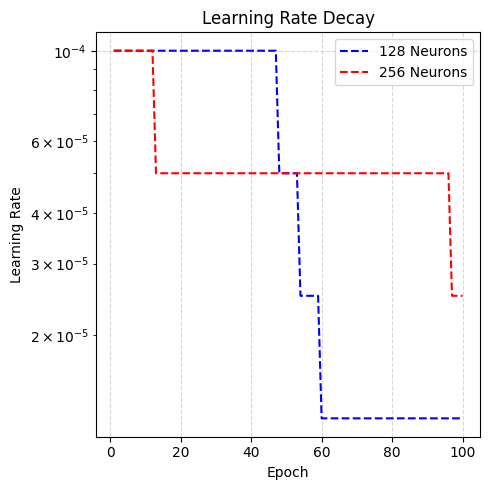

In [ ]:
fig, axs = plt.subplots(1, 1, figsize=(5, 5))

# 2. Learning Rate Schedule
axs.plot(epochs, lr_128, label='128 Neurons', color='blue', linestyle='--')
axs.plot(epochs, lr_256, label='256 Neurons', color='red', linestyle='--')
axs.set_yscale('log')
axs.set_title('Learning Rate Decay')
axs.set_xlabel('Epoch')
axs.set_ylabel('Learning Rate')
axs.legend()
axs.grid(True, ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

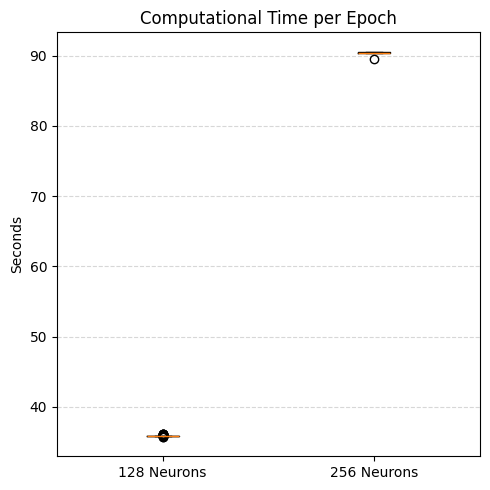

In [ ]:
fig, axs = plt.subplots(1, 1, figsize=(5, 5))

# 3. Epoch Time Boxplot
axs.boxplot([time_128, time_256], tick_labels=['128 Neurons', '256 Neurons'])
axs.set_title('Computational Time per Epoch')
axs.set_ylabel('Seconds')
axs.grid(True, axis='y', ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
import h5py
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# ==============================================================================
# 1. PINN ARCHITECTURE DEFINITION
# ==============================================================================
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.linears = nn.ModuleList()
        for i in range(len(layers) - 1):
            self.linears.append(nn.Linear(layers[i], layers[i+1]))
        self.activation = nn.Tanh()

    def forward(self, x):
        for i in range(len(self.linears) - 1):
            x = self.activation(self.linears[i](x))
        x = self.linears[-1](x)
        return x

# ==============================================================================
# 2. DATASET STATISTICS EXTRACTOR (Required for exact scaling)
# ==============================================================================
def get_normalization_stats(h5_filepath):
    print("Computing global normalization statistics from H5...")
    X_all, Y_all = [], []
    with h5py.File(h5_filepath, "r") as f:
        for group_name in f.keys():
            group = f[group_name]
            Re = group.attrs["reynolds_number"]
            coords = group["coordinates"][:]
            times = group["time"][:]
            vels = group["velocity"][:]
            press = group["pressure"][:]

            T, N = vels.shape[0], vels.shape[1]
            coords_tiled = np.tile(coords, (T, 1))
            times_repeated = np.repeat(times, N).reshape(-1, 1)
            re_array = np.full((T * N, 1), Re)

            X_all.append(np.hstack((coords_tiled, times_repeated, re_array)))
            Y_all.append(np.hstack((vels.reshape(-1, 2), press.reshape(-1, 1))))

    X_raw = np.vstack(X_all)
    Y_raw = np.vstack(Y_all)

    X_mean, X_std = X_raw.mean(axis=0), X_raw.std(axis=0)
    Y_mean, Y_std = Y_raw.mean(axis=0), Y_raw.std(axis=0)

    X_std[X_std == 0] = 1.0
    Y_std[Y_std == 0] = 1.0

    return (torch.tensor(X_mean, dtype=torch.float32),
            torch.tensor(X_std, dtype=torch.float32),
            torch.tensor(Y_mean, dtype=torch.float32),
            torch.tensor(Y_std, dtype=torch.float32))

# ==============================================================================
# 3. HIGH-RESOLUTION PLOTTING ENGINE
# ==============================================================================
def plot_comparative_field(X_grid, Y_grid, true_field, pred_128, pred_256,
                           target_Re, target_t, field_name, cmap, save_name):

    # Calculate Global Relative % Error
    max_val = np.max(np.abs(true_field)) + 1e-8
    err_128 = (np.abs(pred_128 - true_field) / max_val) * 100.0
    err_256 = (np.abs(pred_256 - true_field) / max_val) * 100.0

    fig = plt.figure(figsize=(24, 5))
    gs = GridSpec(1, 5, width_ratios=[1, 1, 1, 1.1, 1.1]) # Extra width for error colorbars

    # Common limits for field plots to ensure visual parity
    vmin, vmax = np.min(true_field), np.max(true_field)

    # 1. Ground Truth FEM
    ax1 = fig.add_subplot(gs[0])
    c1 = ax1.tricontourf(X_grid, Y_grid, true_field, levels=100, cmap=cmap, vmin=vmin, vmax=vmax)
    ax1.set_title(f"FEM Ground Truth ({field_name})", fontsize=14)
    ax1.set_aspect('equal')

    # 2. 128-Neuron Prediction
    ax2 = fig.add_subplot(gs[1])
    ax2.tricontourf(X_grid, Y_grid, pred_128, levels=100, cmap=cmap, vmin=vmin, vmax=vmax)
    ax2.set_title("128-Neuron PINN", fontsize=14)
    ax2.set_aspect('equal')
    ax2.set_yticks([])

    # 3. 256-Neuron Prediction
    ax3 = fig.add_subplot(gs[2])
    ax3.tricontourf(X_grid, Y_grid, pred_256, levels=100, cmap=cmap, vmin=vmin, vmax=vmax)
    ax3.set_title("256-Neuron PINN", fontsize=14)
    ax3.set_aspect('equal')
    ax3.set_yticks([])

    # 4. Error Magnitude 128
    ax4 = fig.add_subplot(gs[3])
    c4 = ax4.tricontourf(X_grid, Y_grid, err_128, levels=100, cmap="inferno", vmin=0, vmax=np.max(err_128))
    plt.colorbar(c4, ax=ax4, label="% Error (Relative to Max)")
    ax4.set_title("128-Neuron % Error", fontsize=14)
    ax4.set_aspect('equal')
    ax4.set_yticks([])

    # 5. Error Magnitude 256
    ax5 = fig.add_subplot(gs[4])
    c5 = ax5.tricontourf(X_grid, Y_grid, err_256, levels=100, cmap="inferno", vmin=0, vmax=np.max(err_128)) # Use 128's max error for direct color scale comparison
    plt.colorbar(c5, ax=ax5, label="% Error (Relative to Max)")
    ax5.set_title("256-Neuron % Error", fontsize=14)
    ax5.set_aspect('equal')
    ax5.set_yticks([])

    plt.suptitle(f"{field_name} Profile Comparison | Re = {target_Re} | t = {target_t}", fontsize=18, y=1.05)
    plt.tight_layout()
    plt.savefig(save_name, dpi=300, bbox_inches='tight')
    plt.close()
    print(f"Saved: {save_name}")

# ==============================================================================
# 4. MAIN EVALUATION ROUTINE
# ==============================================================================
def run_comparative_analysis(h5_file, model_128_path, model_256_path, target_Re=80.0, target_times=[0.5, 1.0]):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Load Stats
    X_mean, X_std, Y_mean, Y_std = get_normalization_stats(h5_file)
    X_mean, X_std = X_mean.to(device), X_std.to(device)
    Y_mean, Y_std = Y_mean.to(device), Y_std.to(device)

    # Initialize and Load Models
    layers_128 = [4, 128, 128, 128, 128, 128, 128, 3]
    layers_256 = [4, 256, 256, 256, 256, 256, 256, 3]

    model_128 = PINN(layers_128).to(device)
    model_256 = PINN(layers_256).to(device)

    model_128.load_state_dict(torch.load(model_128_path, map_location=device))
    model_256.load_state_dict(torch.load(model_256_path, map_location=device))

    model_128.eval()
    model_256.eval()

    # Process H5 Data
    with h5py.File(h5_file, "r") as f:
        # Find the correct group for target_Re
        target_group = None
        for g_name in f.keys():
            if np.isclose(f[g_name].attrs["reynolds_number"], target_Re):
                target_group = f[g_name]
                break

        if target_group is None:
            raise ValueError(f"Reynolds number {target_Re} not found in dataset.")

        times = target_group["time"][:]
        coords = target_group["coordinates"][:]
        X_grid = coords[:, 0]
        Y_grid = coords[:, 1]

        # Iterate over requested time steps
        for t_val in target_times:
            # Find closest time index in the FEM data
            t_idx = np.argmin(np.abs(times - t_val))
            actual_t = times[t_idx]

            # Extract Ground Truth
            u_true = target_group["velocity"][t_idx, :, 0]
            v_true = target_group["velocity"][t_idx, :, 1]
            p_true = target_group["pressure"][t_idx, :]
            vel_mag_true = np.sqrt(u_true**2 + v_true**2)

            # Prepare Network Input
            N = coords.shape[0]
            t_array = np.full((N, 1), actual_t)
            re_array = np.full((N, 1), target_Re)
            X_raw = np.hstack((coords, t_array, re_array))

            X_tensor = torch.tensor(X_raw, dtype=torch.float32, device=device)
            X_norm = (X_tensor - X_mean) / X_std

            # Run Inference
            with torch.no_grad():
                pred_128_norm = model_128(X_norm)
                pred_256_norm = model_256(X_norm)

                # Un-normalize
                pred_128 = pred_128_norm * Y_std + Y_mean
                pred_256 = pred_256_norm * Y_std + Y_mean

            # Extract Physics Variables
            u_128, v_128, p_128 = pred_128[:, 0].cpu().numpy(), pred_128[:, 1].cpu().numpy(), pred_128[:, 2].cpu().numpy()
            u_256, v_256, p_256 = pred_256[:, 0].cpu().numpy(), pred_256[:, 1].cpu().numpy(), pred_256[:, 2].cpu().numpy()

            vel_mag_128 = np.sqrt(u_128**2 + v_128**2)
            vel_mag_256 = np.sqrt(u_256**2 + v_256**2)

            # Generate Plots
            t_str = str(actual_t).replace('.', '_')

            plot_comparative_field(X_grid, Y_grid, vel_mag_true, vel_mag_128, vel_mag_256,
                                   target_Re, actual_t, "Velocity Magnitude", "viridis",
                                   f"compare_vel_Re{target_Re}_t{t_str}.png")

            plot_comparative_field(X_grid, Y_grid, p_true, p_128, p_256,
                                   target_Re, actual_t, "Kinematic Pressure", "coolwarm",
                                   f"compare_press_Re{target_Re}_t{t_str}.png")

# ==============================================================================
# EXECUTION
# ==============================================================================
if __name__ == "__main__":
    h5_dataset = "dimensionless_pinn_dataset_test.h5"
    weights_128 = "parametric_pinn_final_128.pth"  # Ensure this matches your file name
    weights_256 = "parametric_pinn_final_256.pth"      # Assuming this is your 256-width file

    run_comparative_analysis(
        h5_file=h5_dataset,
        model_128_path=weights_128,
        model_256_path=weights_256,
        target_Re=60.0,
        target_times=[0.5, 1.0]
    )

Computing global normalization statistics from H5...


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'dimensionless_pinn_dataset_test.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

# Inference Problem

In [ ]:
import h5py
import numpy as np
import torch

def extract_dataset_statistics(h5_filepath):
    """
    Computes exact mean and standard deviation for inputs [x, y, t, Re]
    and outputs [u, v, p] directly from the training dataset.
    """
    print(f"Extracting exact normalization statistics from {h5_filepath}...")
    X_all, Y_all = [], []

    with h5py.File(h5_filepath, "r") as f:
        for group_name in f.keys():
            group = f[group_name]
            Re = group.attrs["reynolds_number"]

            coords = group["coordinates"][:]  # (N, 2)
            times = group["time"][:]          # (T,)
            vels = group["velocity"][:]       # (T, N, 2)
            press = group["pressure"][:]      # (T, N)

            T, N = vels.shape[0], vels.shape[1]

            coords_tiled = np.tile(coords, (T, 1))
            times_repeated = np.repeat(times, N).reshape(-1, 1)
            re_array = np.full((T * N, 1), Re)

            X_group = np.hstack((coords_tiled, times_repeated, re_array))
            vels_flat = vels.reshape(-1, 2)
            press_flat = press.reshape(-1, 1)
            Y_group = np.hstack((vels_flat, press_flat))

            X_all.append(X_group)
            Y_all.append(Y_group)

    X_raw = torch.tensor(np.vstack(X_all), dtype=torch.float32)
    Y_raw = torch.tensor(np.vstack(Y_all), dtype=torch.float32)

    X_mean = X_raw.mean(dim=0)
    X_std = X_raw.std(dim=0)
    Y_mean = Y_raw.mean(dim=0)
    Y_std = Y_raw.std(dim=0)

    # Prevent zero-division on constant dimensions
    X_std[X_std == 0] = 1.0
    Y_std[Y_std == 0] = 1.0

    X_stats = (X_mean, X_std)
    Y_stats = (Y_mean, Y_std)

    print("✓ Normalization statistics successfully computed!")
    return X_stats, Y_stats

In [ ]:
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# ==============================================================================
# 1. NETWORK ARCHITECTURE DEFINITION
# ==============================================================================
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.linears = nn.ModuleList()
        for i in range(len(layers) - 1):
            self.linears.append(nn.Linear(layers[i], layers[i+1]))
        self.activation = nn.Tanh()

    def forward(self, x):
        for i in range(len(self.linears) - 1):
            x = self.activation(self.linears[i](x))
        x = self.linears[-1](x)
        return x

# ==============================================================================
# 2. SENSOR DATA EXTRACTION
# ==============================================================================
def extract_sparse_sensor_data(h5_file, num_sensors=10):
    """Extracts data from randomly spaced internal nodes, avoiding boundaries."""
    print(f"Extracting {num_sensors} interior sensor nodes from {h5_file}...")

    with h5py.File(h5_file, "r") as f:
        # Assuming single group for the inference file
        group = list(f.keys())[0]
        true_Re = f[group].attrs["reynolds_number"]

        coords = f[group]["coordinates"][:]
        times = f[group]["time"][:]
        vels = f[group]["velocity"][:]
        press = f[group]["pressure"][:]

        # Select the final time step for stable wake flow
        t_idx = -1
        actual_t = times[t_idx]

        # Filter for interior nodes
        interior_mask = (coords[:, 0] > 4.5) & (coords[:, 0] < 8.0) & \
                        (coords[:, 1] > 0.5) & (coords[:, 1] < 2.5)
        interior_indices = np.where(interior_mask)[0]

        # Sample spaced sensors
        np.random.seed(42) # For reproducible reports
        sensor_indices = np.random.choice(interior_indices, size=num_sensors, replace=False)

        sensor_coords = coords[sensor_indices]
        sensor_u = vels[t_idx, sensor_indices, 0].reshape(-1, 1)
        sensor_v = vels[t_idx, sensor_indices, 1].reshape(-1, 1)
        sensor_p = press[t_idx, sensor_indices].reshape(-1, 1)

        X_sensors = np.hstack((sensor_coords, np.full((num_sensors, 1), actual_t)))
        Y_sensors = np.hstack((sensor_u, sensor_v, sensor_p))

    return X_sensors, Y_sensors, true_Re

# ==============================================================================
# 3. REYNOLDS NUMBER INVERSION ALGORITHM
# ==============================================================================
def invert_reynolds_number(model, X_sensors, Y_true_raw, X_stats, Y_stats, device, init_guess=10.0):
    model.eval()

    # Freeze network weights
    for param in model.parameters():
        param.requires_grad = False

    # Unpack stats
    X_mean, X_std = X_stats[0].to(device), X_stats[1].to(device)
    Y_mean, Y_std = Y_stats[0].to(device), Y_stats[1].to(device)

    X_sensors_tensor = torch.tensor(X_sensors, dtype=torch.float32, device=device)
    Y_true = torch.tensor(Y_true_raw, dtype=torch.float32, device=device)
    Y_true_norm = (Y_true - Y_mean) / Y_std

    # Initialize trainable Re parameter
    Re_est = nn.Parameter(torch.tensor([[init_guess]], dtype=torch.float32, device=device))

    # L-BFGS optimizer is highly efficient for single scalar parameter inversion
    optimizer = optim.LBFGS([Re_est], lr=0.5, max_iter=2000, tolerance_grad=1e-9, tolerance_change=1e-11)

    loss_fn = nn.MSELoss()

    def closure():
        optimizer.zero_grad()

        # Expand Re parameter to match batch size
        Re_batch = Re_est.expand(X_sensors_tensor.shape[0], 1)

        # Concat inputs: [x, y, t, Re]
        X_raw = torch.cat([X_sensors_tensor, Re_batch], dim=1)
        X_norm = (X_raw - X_mean) / X_std

        Y_pred_norm = model(X_norm)
        loss = loss_fn(Y_pred_norm, Y_true_norm)

        loss.backward()
        return loss

    # Execute optimization
    optimizer.step(closure)

    # ==========================================================================
    # 4. HESSIAN AND CONFIDENCE INTERVAL CALCULATION
    # ==========================================================================
    Re_batch = Re_est.expand(X_sensors_tensor.shape[0], 1)
    X_raw = torch.cat([X_sensors_tensor, Re_batch], dim=1)
    X_norm = (X_raw - X_mean) / X_std

    # Forward pass requiring gradients for Hessian calculation
    X_norm.requires_grad_(True)
    Re_est.requires_grad_(True)

    Re_batch_grad = Re_est.expand(X_sensors_tensor.shape[0], 1)
    X_raw_grad = torch.cat([X_sensors_tensor, Re_batch_grad], dim=1)
    X_norm_grad = (X_raw_grad - X_mean) / X_std

    Y_pred_norm = model(X_norm_grad)
    final_loss = loss_fn(Y_pred_norm, Y_true_norm)

    # Compute first derivative (Gradient)
    grad = torch.autograd.grad(final_loss, Re_est, create_graph=True)[0]

    # Compute second derivative (Hessian)
    hessian = torch.autograd.grad(grad, Re_est)[0].item()

    # Variance estimation via inverse Hessian approach
    if hessian > 0:
        variance = (2.0 * final_loss.item()) / hessian
        se = np.sqrt(variance)
        ci_95 = 1.96 * se
    else:
        ci_95 = float('inf') # Matrix ill-conditioned

    return Re_est.item(), ci_95, final_loss.item()

# ==============================================================================
# EXECUTION ROUTINE
# ==============================================================================
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Files
    training_h5 = "dimensionless_pinn_dataset.h5"
    inference_h5 = "dimensionless_pinn_dataset_inference_2.h5"

    # 1. Load exact statistics from your original training data
    X_stats, Y_stats = extract_dataset_statistics(training_h5)

    # 2. Extract sparse sensor data from near-wake region
    X_sensors, Y_true, true_Re = extract_sparse_sensor_data(inference_h5, num_sensors=100)
    print(f"\n--- Ground Truth Reynolds Number: {true_Re:.2f} ---\n")

    # 3. Instantiate architectures
    model_128 = PINN([4, 128, 128, 128, 128, 128, 128, 3]).to(device)
    model_256 = PINN([4, 256, 256, 256, 256, 256, 256, 3]).to(device)

    # Load model weights
    model_128.load_state_dict(torch.load("parametric_pinn_final_128.pth", map_location=device))
    model_256.load_state_dict(torch.load("parametric_pinn_final_256.pth", map_location=device))

    # 4. Multi-start parameter inversion to avoid local minima
    init_guesses = [30.0, 50.0, 80.0]

    best_re_128, best_ci_128, min_loss_128 = None, None, float('inf')
    best_re_256, best_ci_256, min_loss_256 = None, None, float('inf')

    for init in init_guesses:
        # Invert 128-width model
        re_est, ci, loss = invert_reynolds_number(model_128, X_sensors, Y_true, X_stats, Y_stats, device, init_guess=init)
        if loss < min_loss_128:
            min_loss_128 = loss
            best_re_128, best_ci_128 = re_est, ci

        # Invert 256-width model
        re_est, ci, loss = invert_reynolds_number(model_256, X_sensors, Y_true, X_stats, Y_stats, device, init_guess=init)
        if loss < min_loss_256:
            min_loss_256 = loss
            best_re_256, best_ci_256 = re_est, ci

    # 5. Print Results
    print("\n================ FINAL INVERSION RESULTS ================")
    print(f"Ground Truth Re: {true_Re:.4f}")
    print(f"128-Width Model: {best_re_128:.4f} ± {best_ci_128:.4f} (95% CI) | Min MSE: {min_loss_128:.2e}")
    print(f"256-Width Model: {best_re_256:.4f} ± {best_ci_256:.4f} (95% CI) | Min MSE: {min_loss_256:.2e}")
    print("=========================================================")

Extracting exact normalization statistics from dimensionless_pinn_dataset.h5...
✓ Normalization statistics successfully computed!
Extracting 100 interior sensor nodes from dimensionless_pinn_dataset_inference_2.h5...

--- Ground Truth Reynolds Number: 18.00 ---


================ FINAL INVERSION RESULTS ================
Ground Truth Re: 18.0000
128-Width Model: 20.2287 ± 7.9732 (95% CI) | Min MSE: 5.21e-03
256-Width Model: 18.8226 ± 7.2281 (95% CI) | Min MSE: 5.06e-03


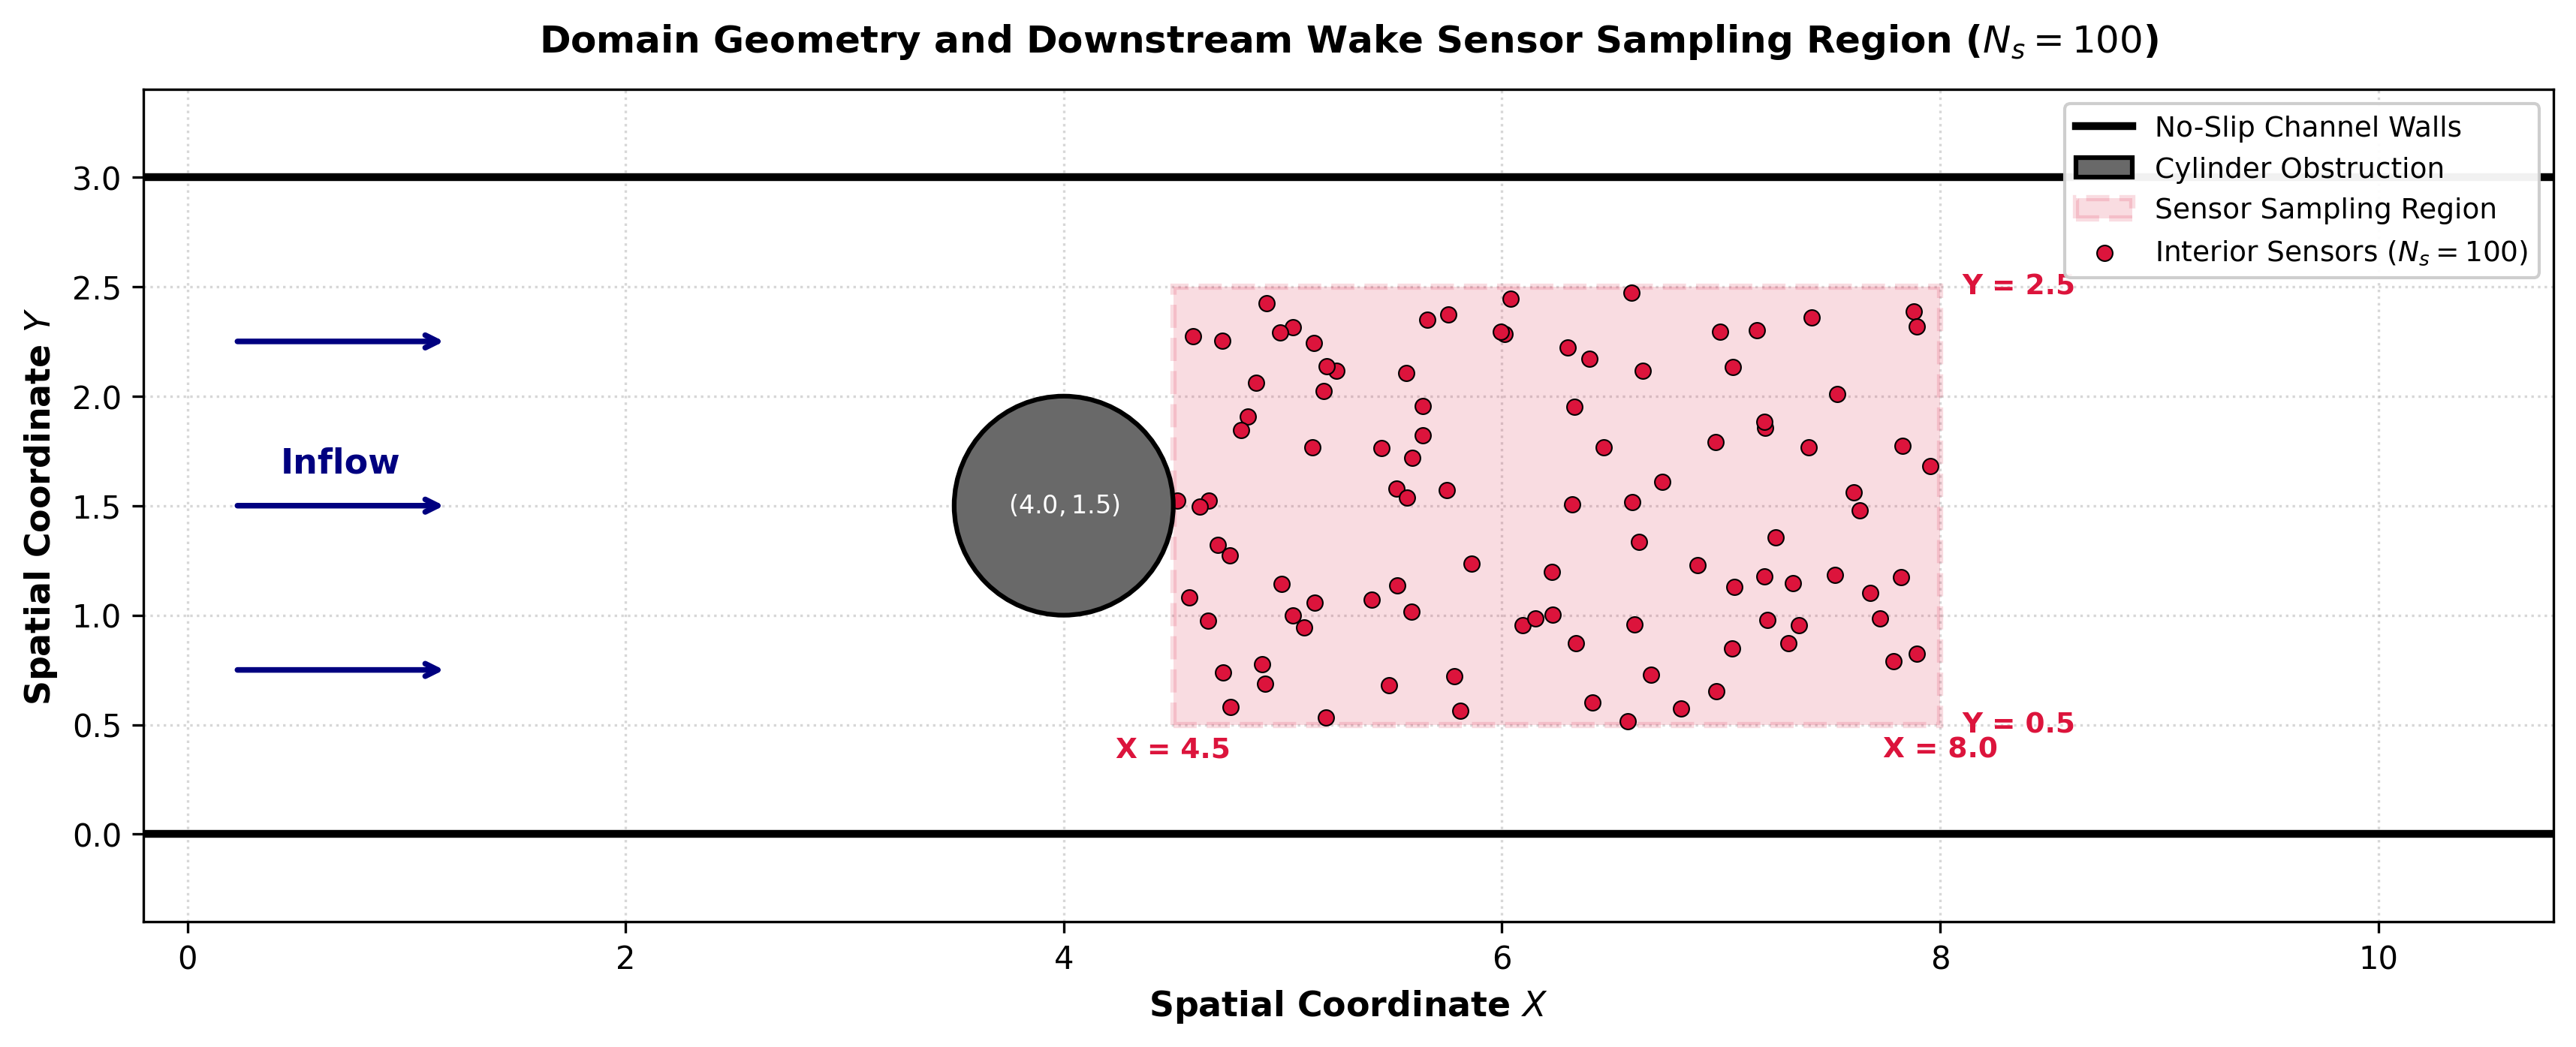

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

def plot_sensor_sampling_region():
    # Set up publication-quality figure
    fig, ax = plt.subplots(figsize=(12, 4.5), dpi=300)

    # 1. Channel Geometry Parameters
    x_min, x_max = 0.0, 10.0
    y_min, y_max = 0.0, 3.0

    cylinder_center = (4.0, 1.5)
    cylinder_radius = 0.5

    # 2. Bounding Box for Sensor Sampling Region
    # (x in [4.5, 8.0], y in [0.5, 2.5])
    box_x_min, box_x_max = 4.5, 8.0
    box_y_min, box_y_max = 0.5, 2.5

    # Generate 100 reproducible interior sensor nodes within the bounding box
    np.random.seed(42)
    sensor_x = np.random.uniform(box_x_min, box_x_max, 100)
    sensor_y = np.random.uniform(box_y_min, box_y_max, 100)

    # 3. Draw Channel Domain
    # Channel Walls
    ax.axhline(y=y_min, color='black', linewidth=2.5, label='No-Slip Channel Walls')
    ax.axhline(y=y_max, color='black', linewidth=2.5)

    # Cylinder Obstruction
    cylinder = patches.Circle(cylinder_center, cylinder_radius,
                              facecolor='dimgray', edgecolor='black', linewidth=1.5, zorder=4, label='Cylinder Obstruction')
    ax.add_patch(cylinder)

    # Sensor Sampling Region Bounding Box
    box_width = box_x_max - box_x_min
    box_height = box_y_max - box_y_min
    sensor_box = patches.Rectangle((box_x_min, box_y_min), box_width, box_height,
                                   linewidth=2, edgecolor='crimson', facecolor='crimson',
                                   alpha=0.15, linestyle='--', zorder=2, label='Sensor Sampling Region')
    ax.add_patch(sensor_box)

    # Scatter Sensor Nodes
    ax.scatter(sensor_x, sensor_y, color='crimson', s=25, marker='o',
               edgecolor='black', linewidth=0.5, zorder=3, label='Interior Sensors ($N_s=100$)')

    # 4. Schematics for Flow Direction and Domain Annotations
    # Flow Direction Arrows
    for y_pos in [0.75, 1.5, 2.25]:
        ax.annotate('', xy=(1.2, y_pos), xytext=(0.2, y_pos),
                    arrowprops=dict(arrowstyle="->", color="navy", lw=1.8))
    ax.text(0.7, 1.65, 'Inflow', color='navy', fontsize=11, fontweight='bold', ha='center')

    # Dimension Annotations
    ax.text(cylinder_center[0], cylinder_center[1], '$(4.0, 1.5)$', color='white',
            fontsize=8, ha='center', va='center', fontweight='bold', zorder=5)

    # Bounding Box Coordinate Labels
    ax.text(box_x_min, box_y_min - 0.15, f'X = {box_x_min}', color='crimson', fontsize=9, ha='center', fontweight='bold')
    ax.text(box_x_max, box_y_min - 0.15, f'X = {box_x_max}', color='crimson', fontsize=9, ha='center', fontweight='bold')
    ax.text(box_x_max + 0.1, box_y_min, f'Y = {box_y_min}', color='crimson', fontsize=9, va='center', fontweight='bold')
    ax.text(box_x_max + 0.1, box_y_max, f'Y = {box_y_max}', color='crimson', fontsize=9, va='center', fontweight='bold')

    # 5. Styling and Formatting
    ax.set_xlim(x_min - 0.2, x_max + 0.8)
    ax.set_ylim(y_min - 0.4, y_max + 0.4)
    ax.set_aspect('equal')

    ax.set_xlabel('Spatial Coordinate $X$', fontsize=11, fontweight='bold')
    ax.set_ylabel('Spatial Coordinate $Y$', fontsize=11, fontweight='bold')
    ax.set_title('Domain Geometry and Downstream Wake Sensor Sampling Region ($N_s = 100$)',
                 fontsize=12, fontweight='bold', pad=12)

    ax.grid(True, linestyle=':', alpha=0.5)
    ax.legend(loc='upper right', framealpha=0.95, fontsize=9)

    plt.tight_layout()
    plt.savefig('sensor_sampling_region.png', dpi=300)
    plt.show()

if __name__ == '__main__':
    plot_sensor_sampling_region()